# Self Learning Assignment:

## Instructions:
 1. Load the provided dataset into a Pandas DataFrame named df. 
 2. Write clean, commented Python code for each question.
 3. Ensure all plots have appropriate titles, labels, and legends where necessary.
    
## Tasks: 

 1. Check and replace all missing values in the Units_Sold column with the median value of that specific column
 2. Calculate the total units sold and the average unit price for each Store_name. Identify which store has generated the highest total units sold
 3. Create a new column named Total_Revenue, calculated by multiplying Units_Sold by Unit_Price
 4. Group the data by Region_ID and calculate the sum of Total_Revenue for each region
 5. Use Matplotlib to plot a bar chart showing Region_ID on the x-axis and the sum of Total_Revenue on the y-axis. Set the bar colour to green, add a grid on the y-axis, and give the chart a clear title
 6. Create a scatter plot using Matplotlib mapping Unit_Price on the x-axis against Units_Sold on the y-axi

### Write plot interpretation in your own words


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# RIGIONAL SALES DATA CONTAINS 4 REGIONS AND RIGION WISE
df = pd.read_csv("regional_sales_data.txt", sep=" ") 
df

,Region_ID,Units_Sold,Unit_Price,Store_name,Country
0,REG_01,NaN,34.75,Beta_Retail,UK
1,REG_01,149.0,17.82,Delta_Shop,India
2,REG_01,NaN,30.94,Epsilon_Hub,India
3,REG_02,149.0,47.75,Delta_Shop,Canada
4,REG_03,11.0,78.29,Beta_Retail,Germany
5,REG_03,65.0,96.14,Gamma_Store,India
6,REG_01,101.0,86.27,Epsilon_Hub,USA
7,REG_01,147.0,21.23,Delta_Shop,India
8,REG_03,102.0,61.96,Alpha_Mart,India
9,REG_02,30.0,86.97,Alpha_Mart,Germany


### 1. Check and replace all missing values in the Units_Sold column with the median value of that specific column

In [3]:
df.isnull()

,Region_ID,Units_Sold,Unit_Price,Store_name,Country
0,False,True,False,False,False
1,False,False,False,False,False
2,False,True,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,False,False,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


In [4]:
df.isnull().sum()

Region_ID     0
Units_Sold    5
Unit_Price    0
Store_name    0
Country       0
dtype: int64

In [5]:
median = df["Units_Sold"].median()
median

100.0

In [6]:
df.fillna({"Units_Sold" : df["Units_Sold"].median()}, inplace=True)
df

,Region_ID,Units_Sold,Unit_Price,Store_name,Country
0,REG_01,100.0,34.75,Beta_Retail,UK
1,REG_01,149.0,17.82,Delta_Shop,India
2,REG_01,100.0,30.94,Epsilon_Hub,India
3,REG_02,149.0,47.75,Delta_Shop,Canada
4,REG_03,11.0,78.29,Beta_Retail,Germany
5,REG_03,65.0,96.14,Gamma_Store,India
6,REG_01,101.0,86.27,Epsilon_Hub,USA
7,REG_01,147.0,21.23,Delta_Shop,India
8,REG_03,102.0,61.96,Alpha_Mart,India
9,REG_02,30.0,86.97,Alpha_Mart,Germany


### 2. Calculate the total units sold and the average unit price for each Store_name. Identify which store has generated the highest total units sold

In [7]:
df1 = df.groupby("Store_name").agg(
    Total_Unit_Sold = ("Units_Sold","sum"),
    Average_Unit_Price = ("Unit_Price","mean")
)
df1

,Total_Unit_Sold,Average_Unit_Price
Store_name,,
Alpha_Mart,881.0,62.286667
Beta_Retail,1042.0,59.816667
Delta_Shop,1001.0,40.494000
Epsilon_Hub,1376.0,59.321333
Gamma_Store,1057.0,55.271818


In [8]:
top = df1["Total_Unit_Sold"].max()
top

1376.0

In [9]:
top_store = df1["Total_Unit_Sold"].idxmax()
print(f"Top Store : {top_store}")

Top Store : Epsilon_Hub


### 3.Create a new column named Total_Revenue, calculated by multiplying Units_Sold by Unit_Price

In [10]:
df["Total_Revenue"] = df["Units_Sold"] * df["Unit_Price"]
df

,Region_ID,Units_Sold,Unit_Price,Store_name,Country,Total_Revenue
0,REG_01,100.0,34.75,Beta_Retail,UK,3475.00
1,REG_01,149.0,17.82,Delta_Shop,India,2655.18
2,REG_01,100.0,30.94,Epsilon_Hub,India,3094.00
3,REG_02,149.0,47.75,Delta_Shop,Canada,7114.75
4,REG_03,11.0,78.29,Beta_Retail,Germany,861.19
5,REG_03,65.0,96.14,Gamma_Store,India,6249.10
6,REG_01,101.0,86.27,Epsilon_Hub,USA,8713.27
7,REG_01,147.0,21.23,Delta_Shop,India,3120.81
8,REG_03,102.0,61.96,Alpha_Mart,India,6319.92
9,REG_02,30.0,86.97,Alpha_Mart,Germany,2609.10


### 4. Group the data by Region_ID and calculate the sum of Total_Revenue for each region

In [11]:
df2 = df.groupby("Region_ID").agg(Total_Revenue_Sum=("Total_Revenue","sum"))
df2

,Total_Revenue_Sum
Region_ID,
REG_01,117092.28
REG_02,63404.82
REG_03,62422.10
REG_04,52051.47


### 5. Use Matplotlib to plot a bar chart showing Region_ID on the x-axis and the sum of Total_Revenue on the y-axis. Set the bar colour to green, add a grid on the y-axis, and give the chart a clear title


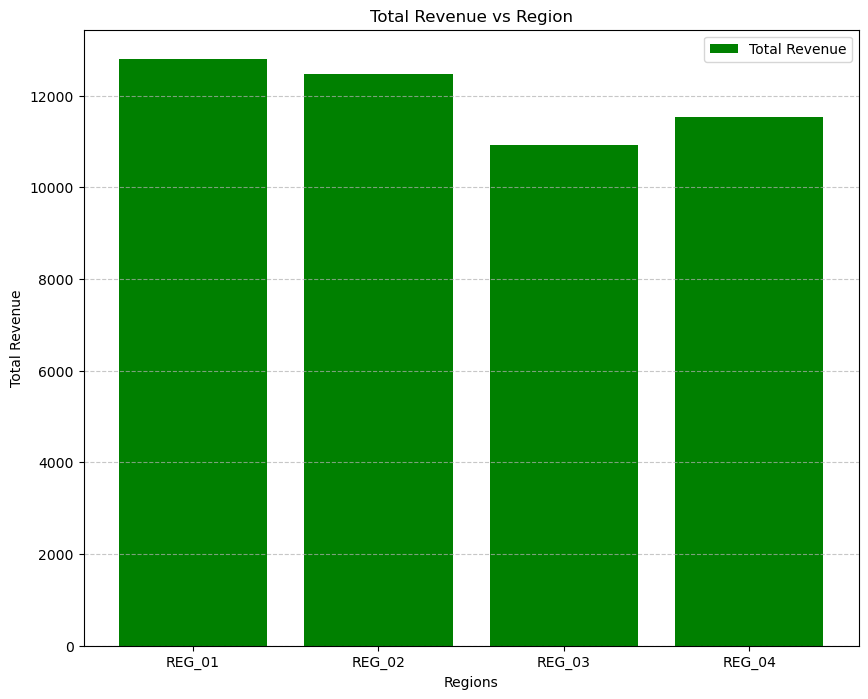

In [12]:
plt.figure(figsize=(10,8))
plt.bar(df["Region_ID"],df["Total_Revenue"],color="green",label="Total Revenue")
plt.xlabel("Regions")
plt.ylabel("Total Revenue")
plt.title("Total Revenue vs Region")
plt.grid(axis="y",linestyle="--", alpha=0.7)
plt.legend()
plt.show()


### 6. Create a scatter plot using Seaborn mapping Unit_Price on the x-axis against Units_Sold on the y-axi

Text(0.5, 1.0, 'Units_Sold vs Unit_Price by Region')

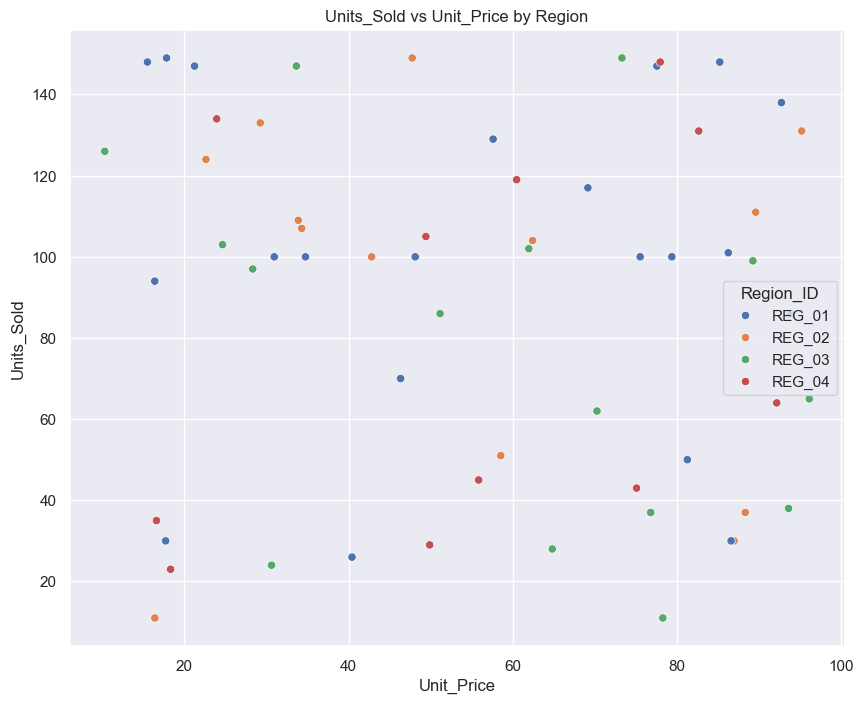

In [13]:
plt.figure(figsize=(10,8))
sns.set_theme(style="darkgrid")
sns.scatterplot(df,x="Unit_Price",y="Units_Sold",hue="Region_ID")
plt.title("Units_Sold vs Unit_Price by Region")